In [29]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

### 1) Loading the Taxis Dataset

In [30]:
 
df = sns.load_dataset("taxis")
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


### 2) Handling Missing Values

In [11]:
# Check for missing values
df.isnull().sum()


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [31]:
# Impute missing values
### Replace missing numerical values using Median

num_cols = df.select_dtypes(include=['number']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
   

In [32]:
### Replace missing categorical values using Mode

cat_cols = df.select_dtypes(include=['object', 'category']).columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

        

C:\Users\SANA\AppData\Local\Temp\ipykernel_30600\2755309078.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns


In [33]:
# remove rows with missing values to maintain data integrity.

df.dropna(inplace=True)

In [34]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

### 3) Visualizations using Matplotlib/Pandas Plot:

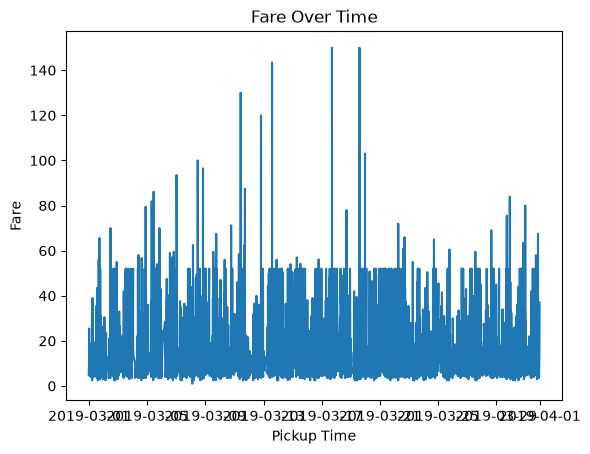

In [35]:
# # Line Chart
# Plot a line chart to visualize the fare over time, using the pickup timestamp as the
# x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime
# format before plotting.

df['pickup'] = pd.to_datetime(df['pickup'])    # Convert pickup into datetime format
df = df.sort_values('pickup')                  # Sorting the pickup time
plt.plot(df['pickup'], df['fare'])             
plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare')
plt.show()

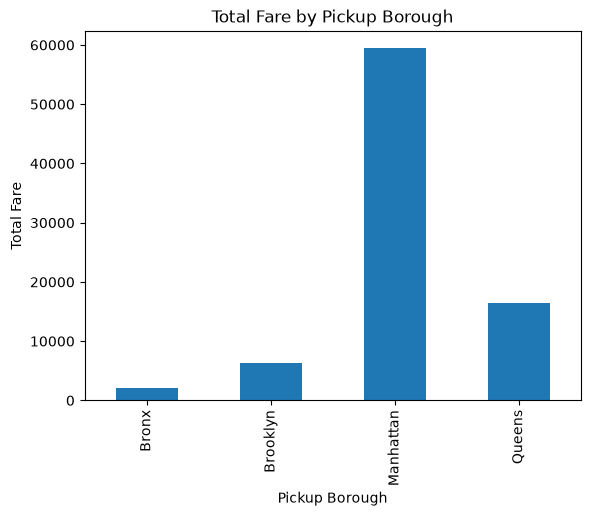

In [36]:
# Bar Chart
# Create a bar chart to show the total fare for each pickup_borough. Group the data
# by pickup_borough and sum the fare for each group.


borough_fare = df.groupby('pickup_borough')['fare'].sum()

borough_fare.plot(kind='bar')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.show()

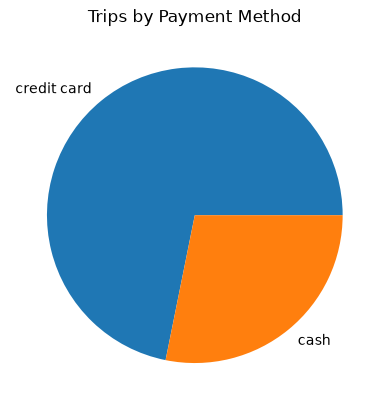

In [37]:
# Pie Chart
# Plot a pie chart showing the distribution of trips based on the payment method (credit
# card, cash, etc.). Each slice should represent the count of trips for a specific payment
# method.

payment_count = df['payment'].value_counts()

payment_count.plot(kind='pie')

plt.title('Trips by Payment Method')
plt.show()

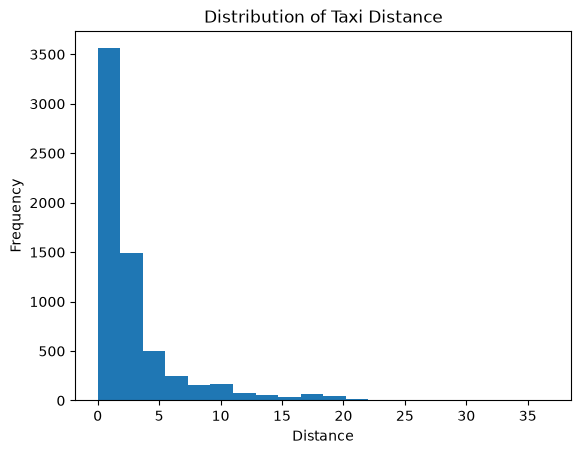

In [38]:
# Histogram
# Create a histogram to visualize the distribution of distance. Customize the number of
# bins for better granularity and ensure the plot is easy to interpret.


plt.hist(df['distance'], bins=20)

plt.title('Distribution of Taxi Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

plt.show()

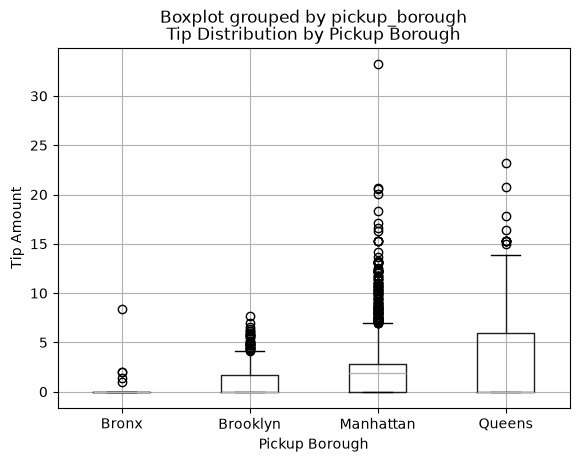

In [40]:
# Box Plot
# Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
# Use pickup_borough as the categorical axis and tip as the numeric axis.


df.boxplot(column='tip', by='pickup_borough')

plt.title('Tip Distribution by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')



plt.show()

### Visualizations using Seaborn:

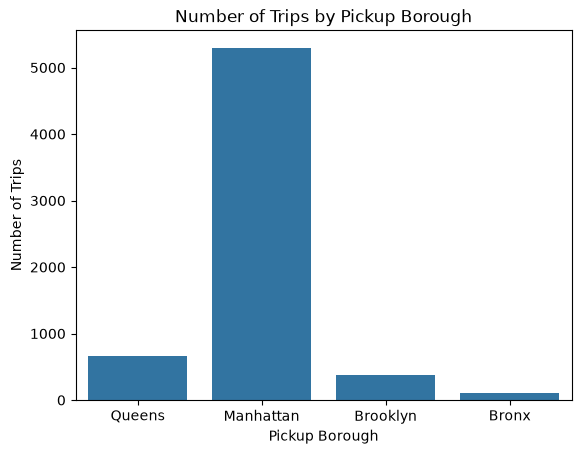

In [41]:
# Count Plot
# Create a count plot to visualize the number of trips in each pickup_borough. The
# x-axis should represent the boroughs, and the y-axis should show the count of trips.


sns.countplot(data=df, x='pickup_borough')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.show()

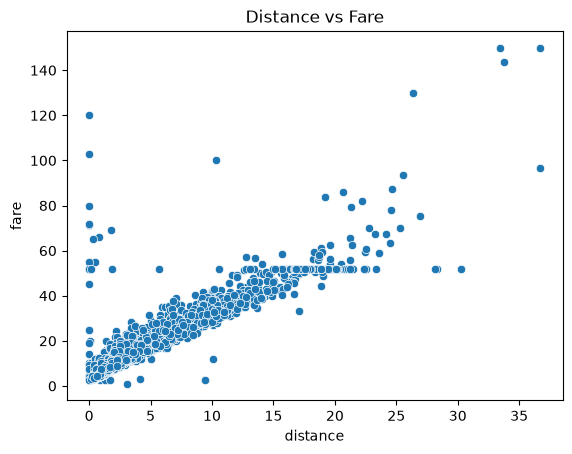

In [43]:
# Scatter Plot
# Plot a scatter plot to show the relationship between distance and fare. Use
# distance on the x-axis and fare on the y-axis to visualize any correlation. Color the
# points based on the pickup_borough to differentiate the trips by their respective
# boroughs.


sns.scatterplot(data=df, x='distance', y='fare')

plt.title('Distance vs Fare')

plt.show()

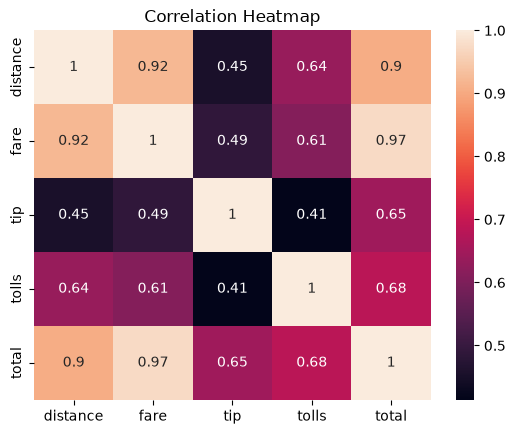

In [44]:
# Heatmap
# Plot a heatmap to visualize the correlation between numerical variables such as
# distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
# relationships.



numerical_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]
corr = numerical_data.corr()
sns.heatmap(corr, annot=True)
plt.title('Correlation Heatmap')

plt.show()

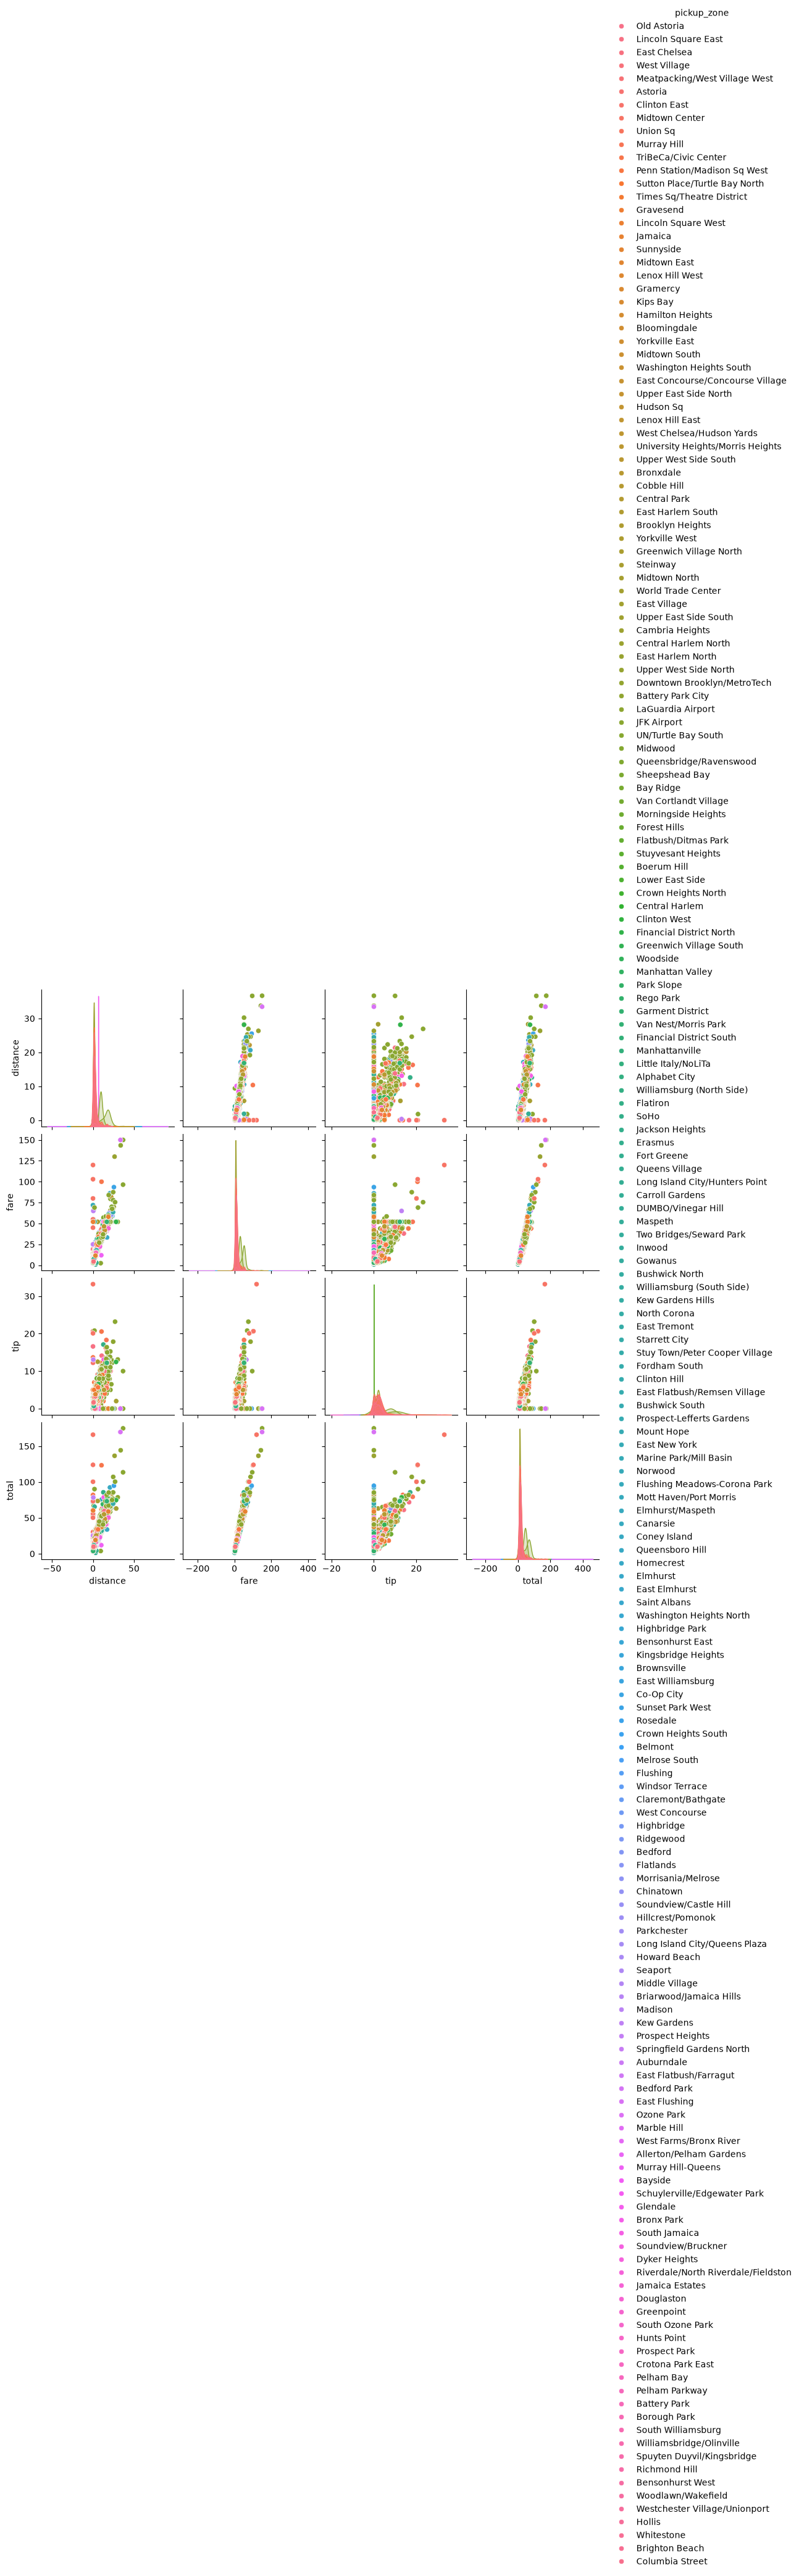

In [50]:
# Pair Plot
# Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
# and total. Color the data points according to the pickup_zone method to compare
# how different zones affect these variables.

sns.pairplot(df, vars=['distance', 'fare', 'tip', 'total'],hue='pickup_zone')

plt.show()

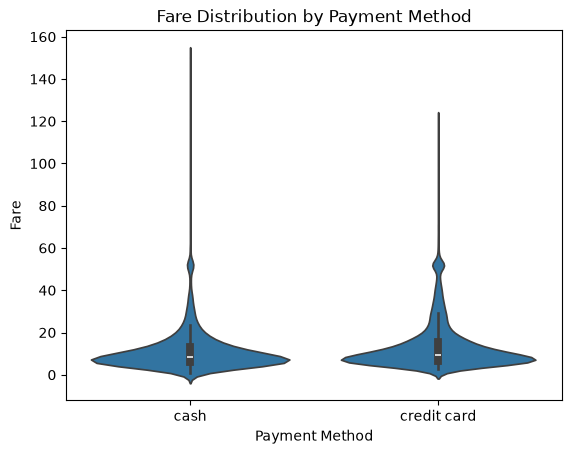

In [51]:
# Violin Plot
# Plot a violin plot to show the distribution of fare for each payment method. Use the
# payment method as the categorical axis and fare as the numeric axis to visualize its
# distribution.


sns.violinplot(data=df, x='payment', y='fare')

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')

plt.show()